In [4]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from RF.rflocate import RFMapList, load_rfmap
from HD.profiles import load_hd_tc, hd_profiles
from Utils.plotting import plot_hd_tuning_curve
from Utils.statistic_utils import smooth_tuning_curve, tuning_curve_reference_radii
from HD.tuning_curve_utils import classify_hd


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
base_dir = r"/mnt/senzailab/Kai/#Recording/m22"
date = "261015"
num_of_rec = 9
rf_session_id = 2
rf_response_window_s = (0.0, 0.2)
rf_arrow_length = 0.42  # Relative to the unit circle; direction only.
probe_name = "A"
bins = 30
hd_class = 3
kappa_cutoff = 0.25
smooth_sigma = 1  # In angular bins.

session_dir = f"{base_dir}/{date}/{date}_{num_of_rec}"


In [6]:
hd_tc = load_hd_tc(f"{session_dir}/data/tuning_curves/Probe{probe_name}/tuning_curves.tc")
classify_hd(hd_tc, kappa_cutoff=kappa_cutoff)
tc = hd_profiles(hd_tc, probe=probe_name, bins=bins, hd_class=hd_class)
tc.columns = tc.columns % 360


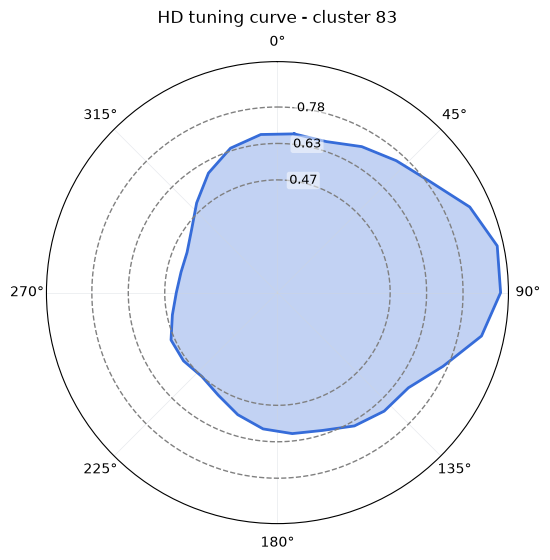

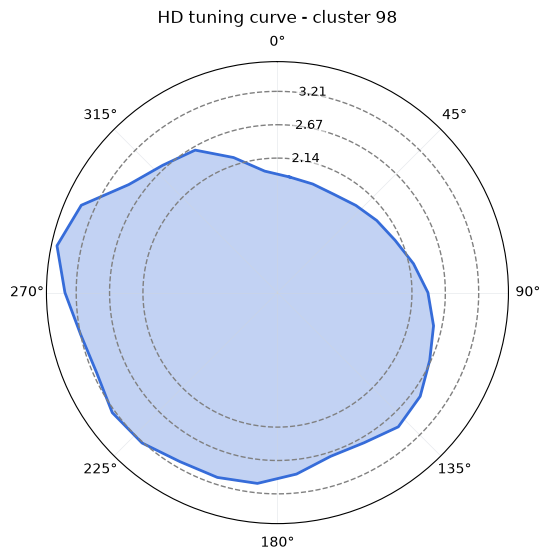

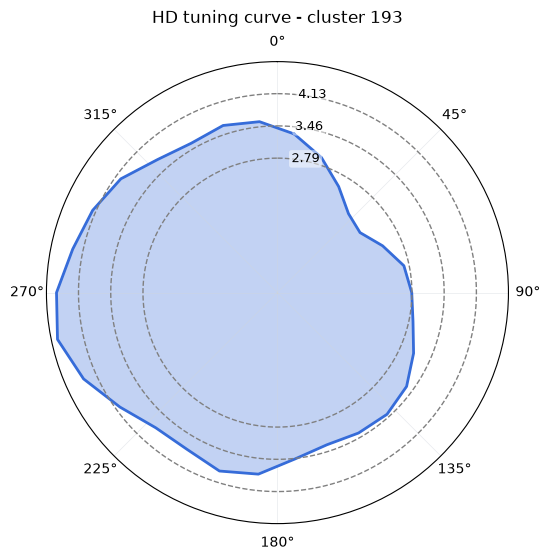

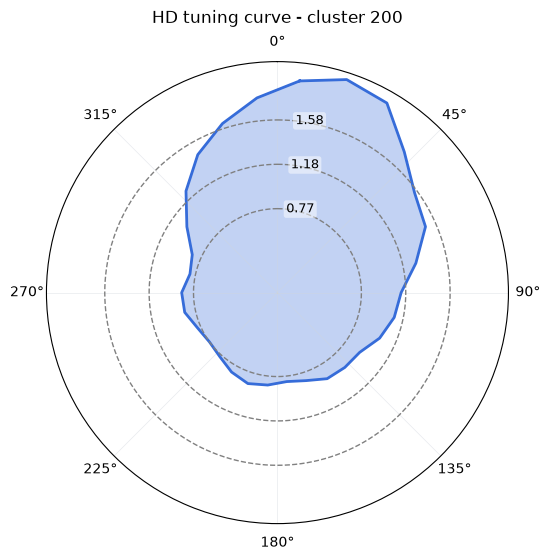

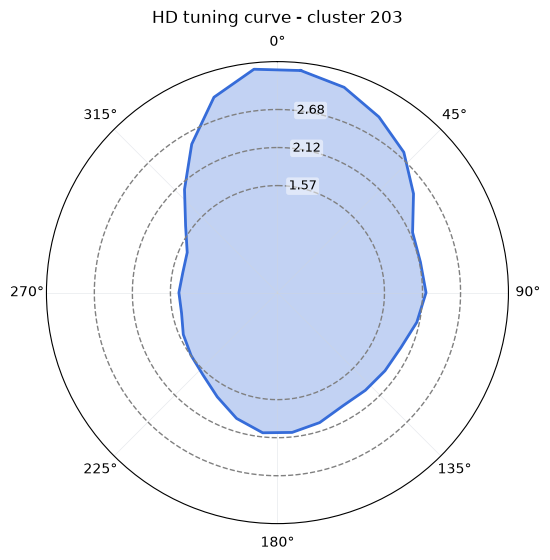

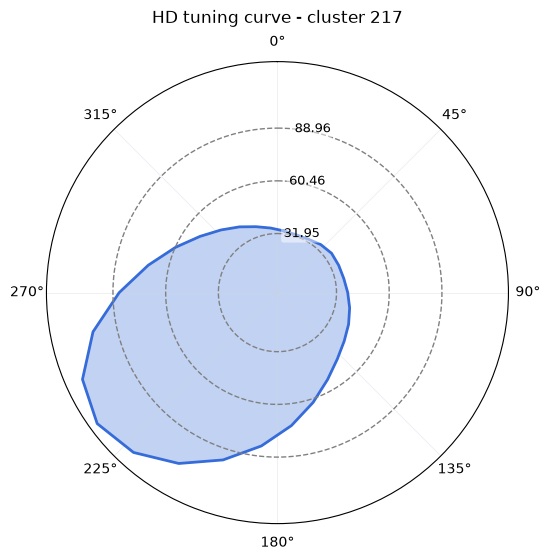

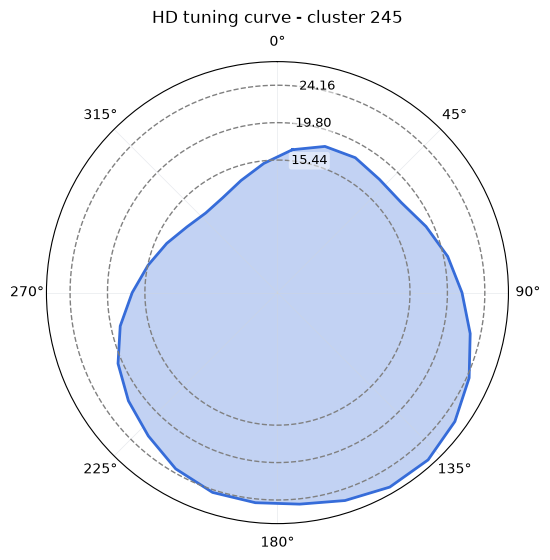

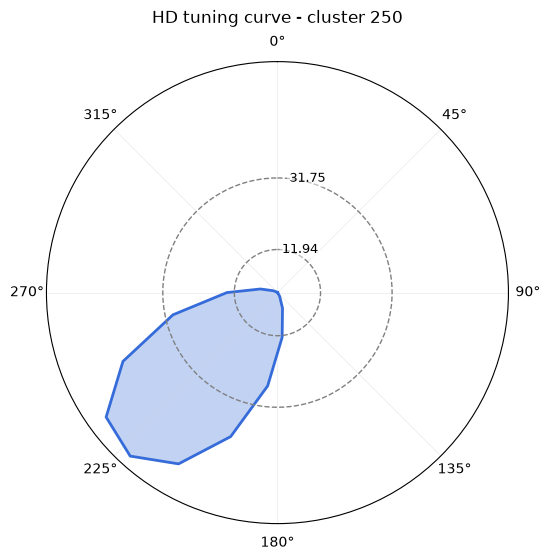

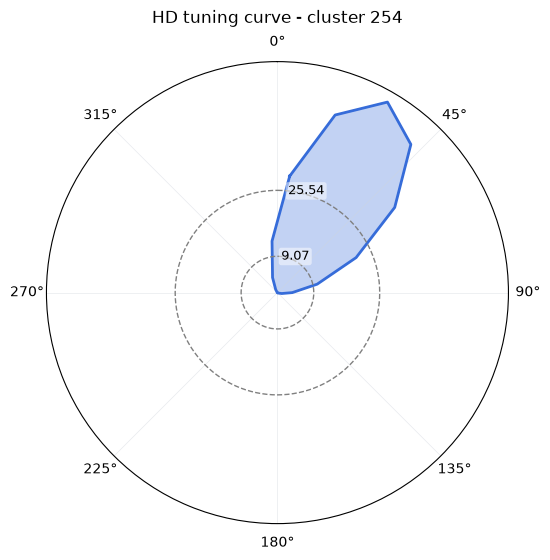

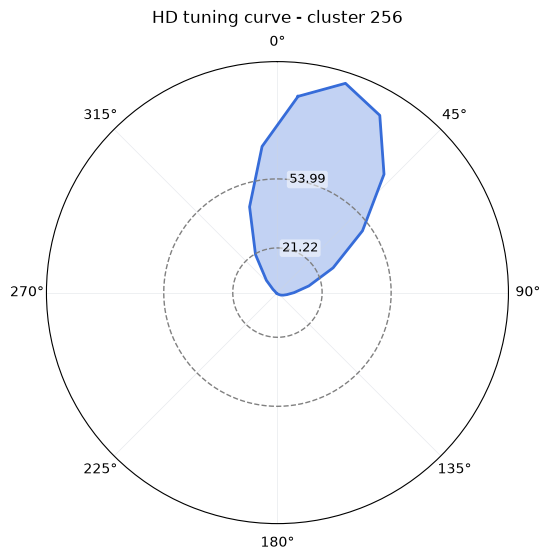

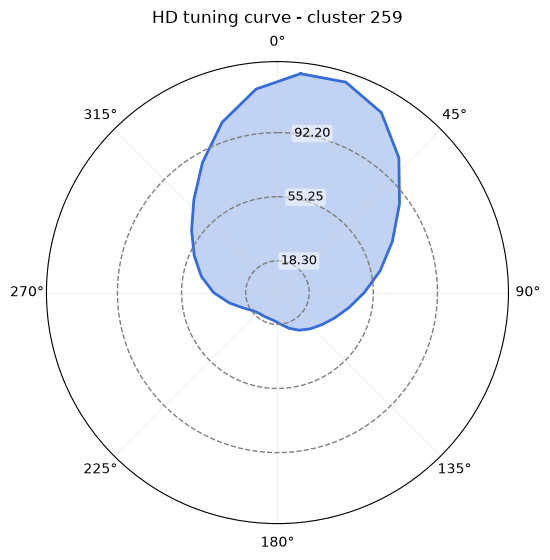

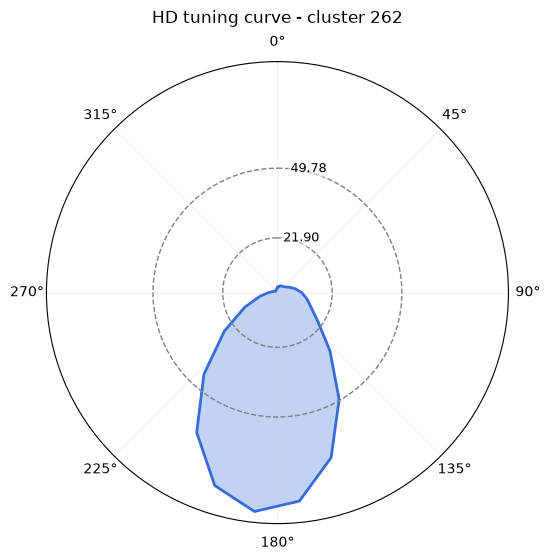

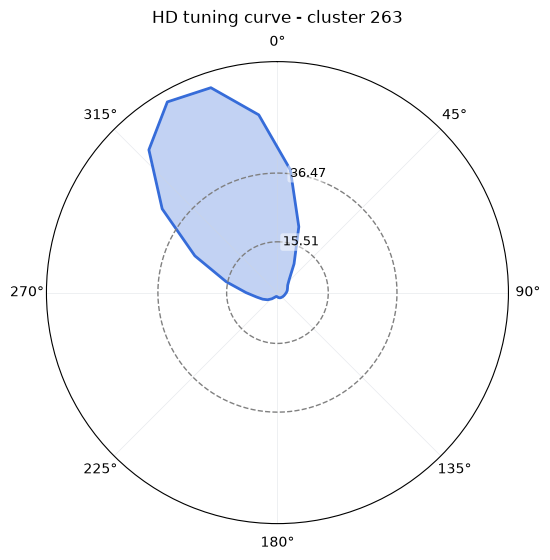

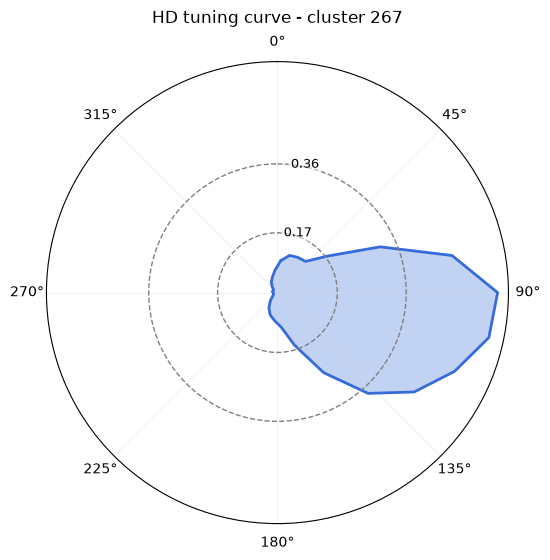

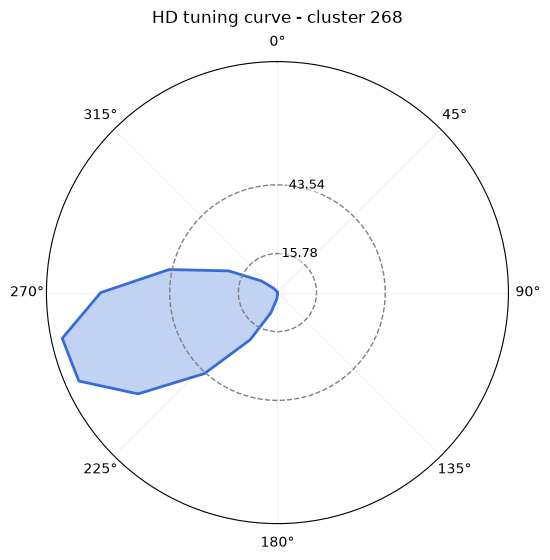

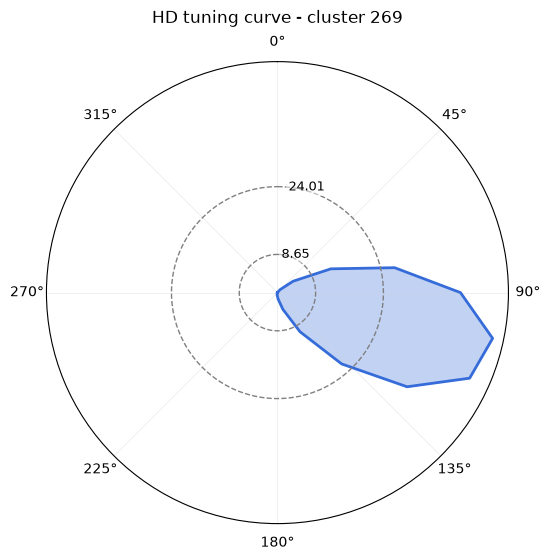

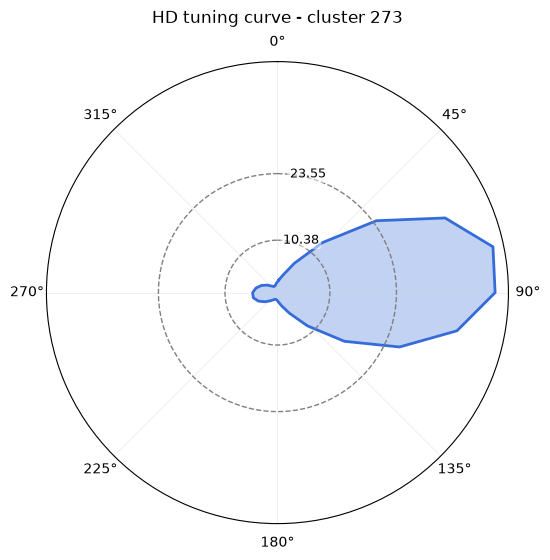

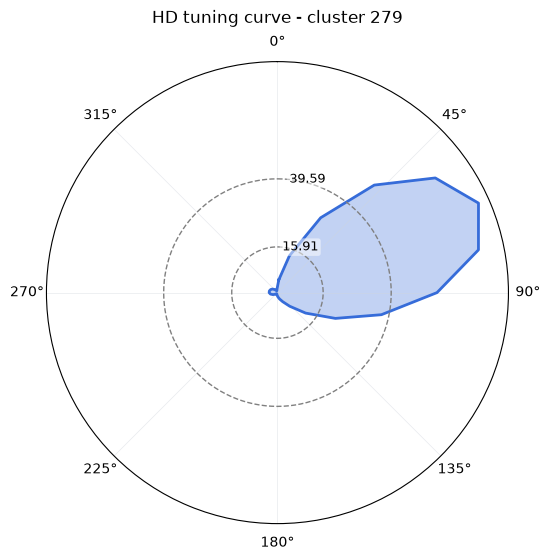

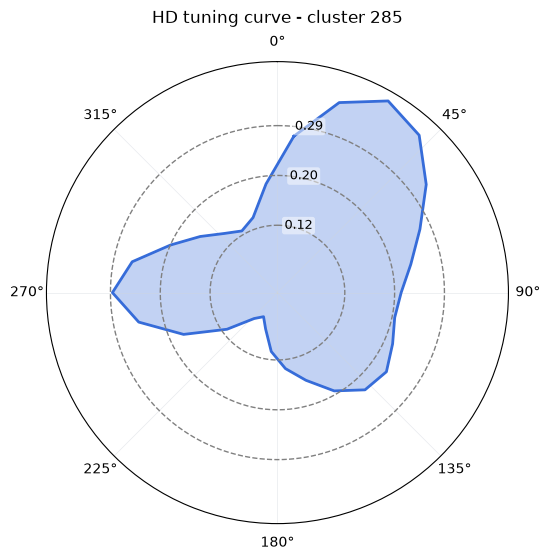

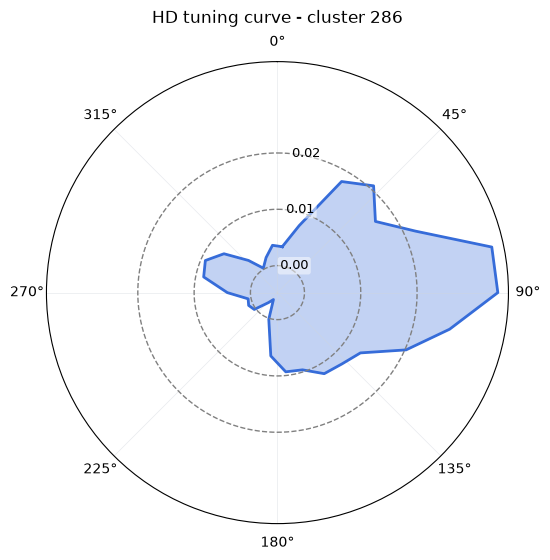

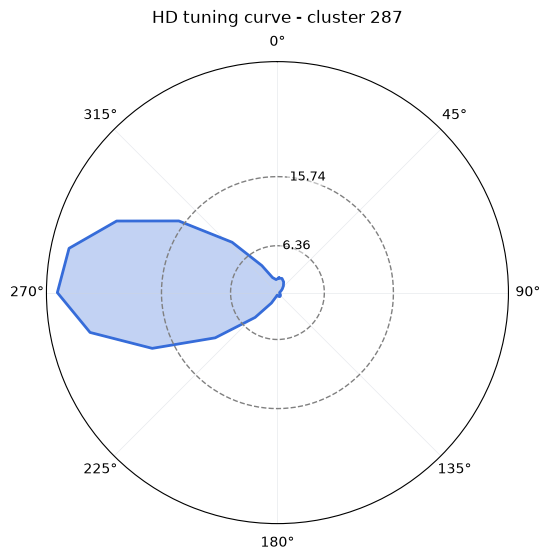

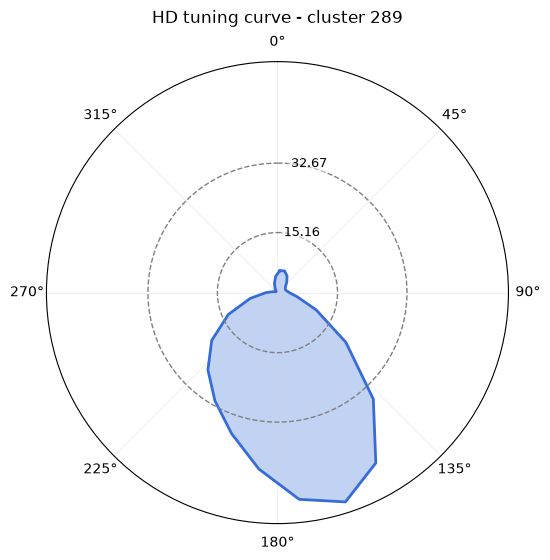

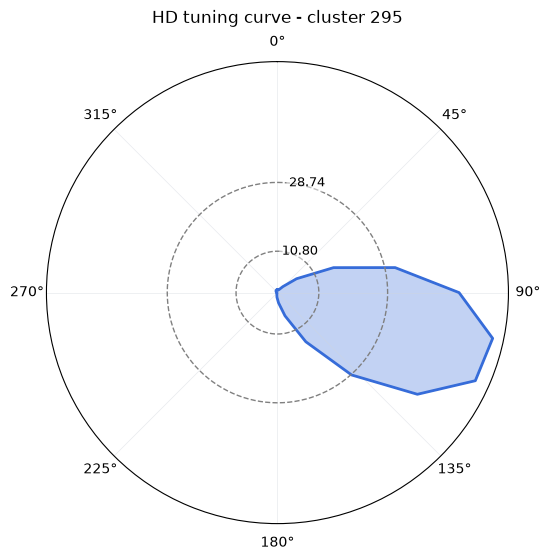

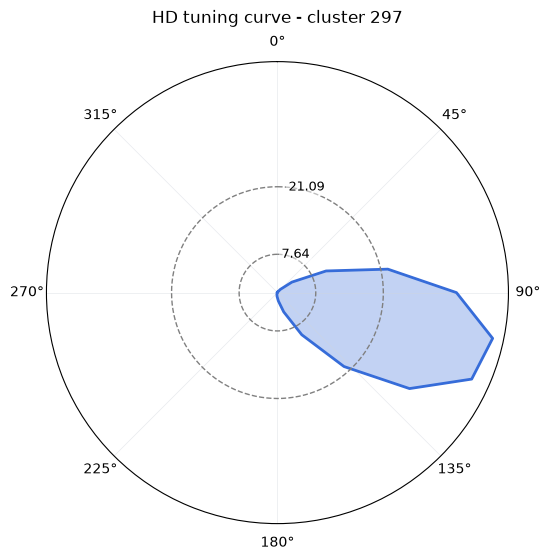

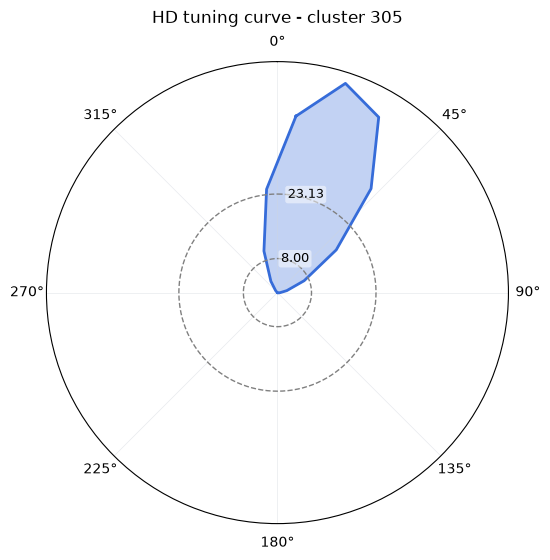

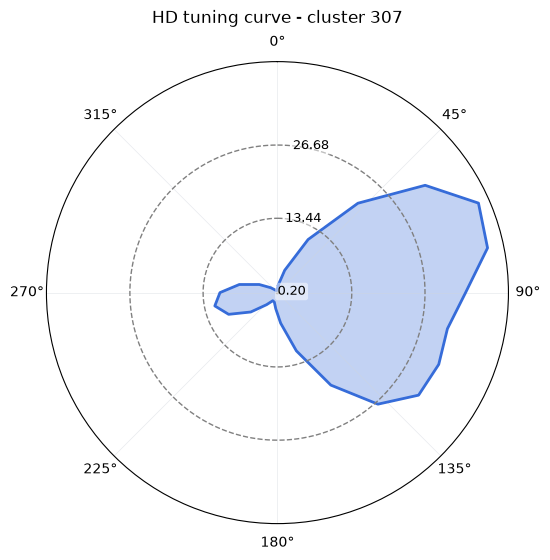

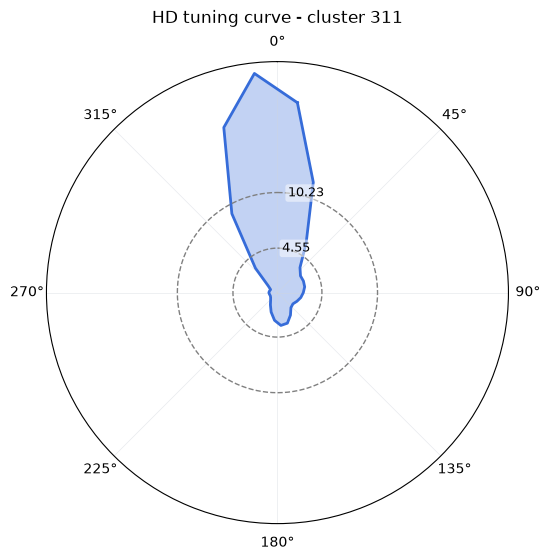

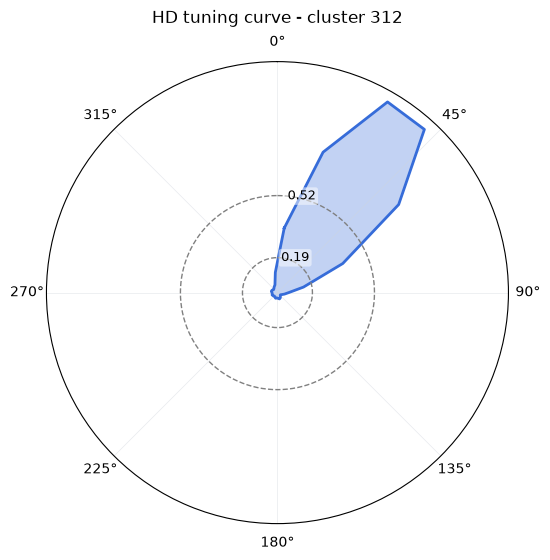

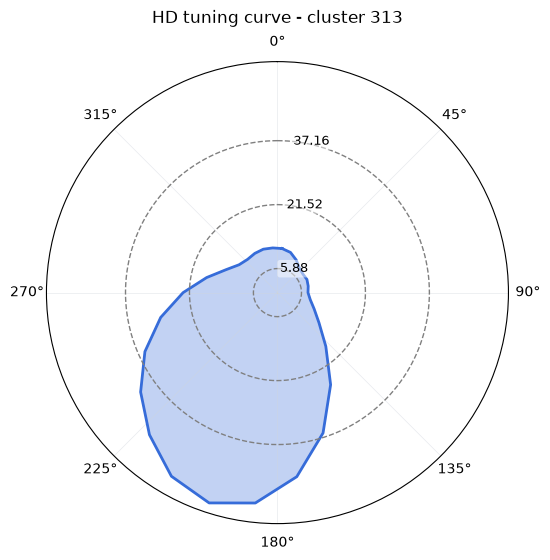

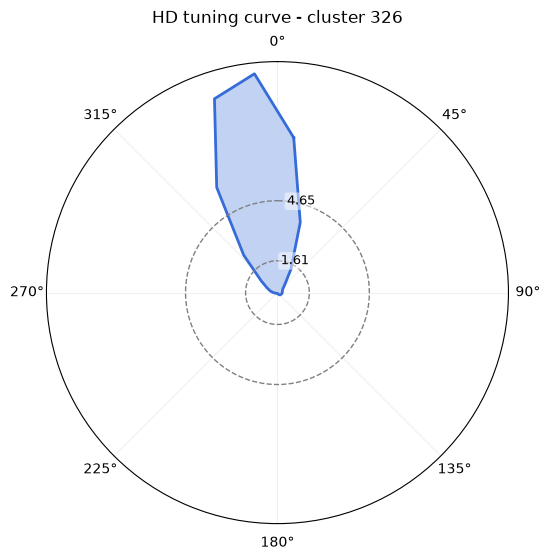

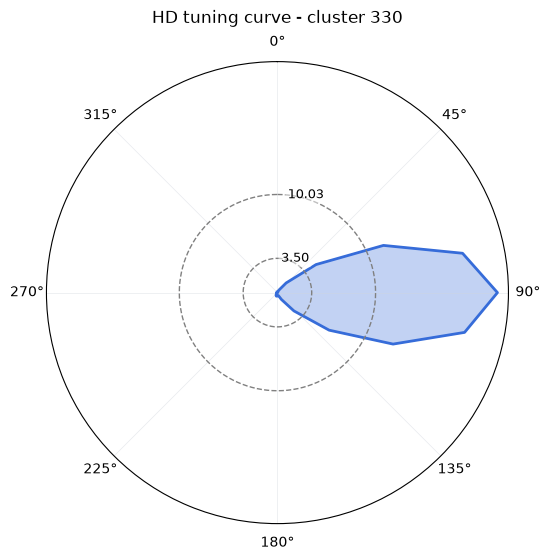

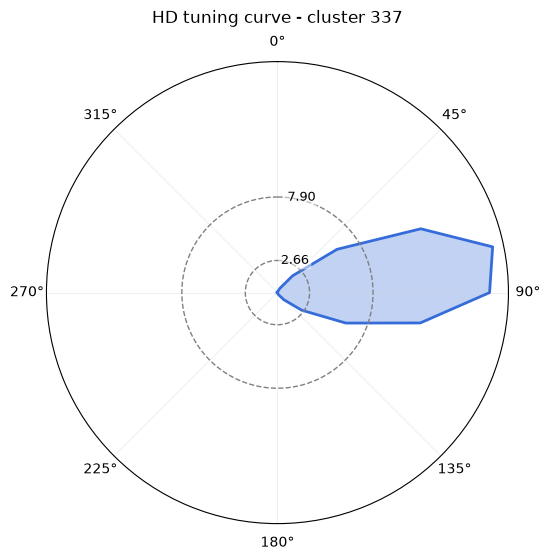

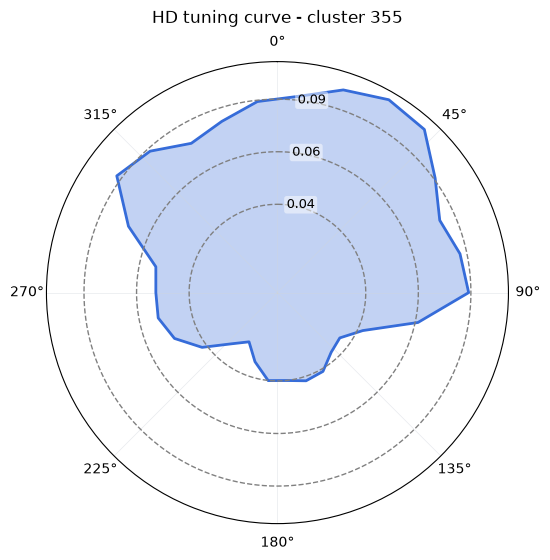

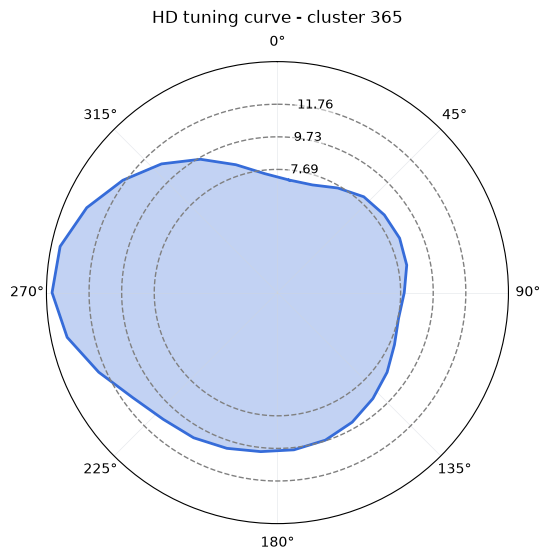

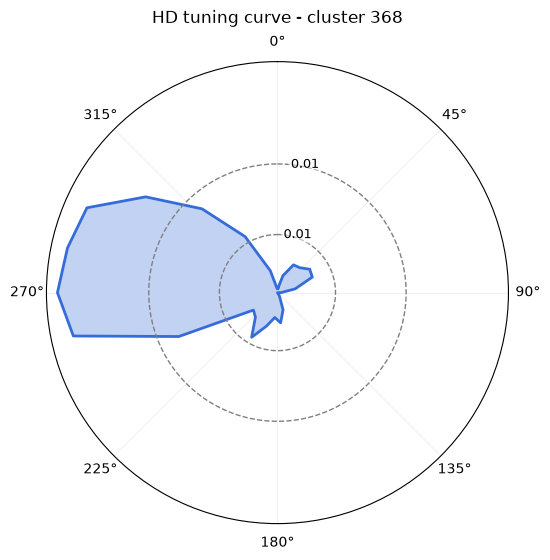

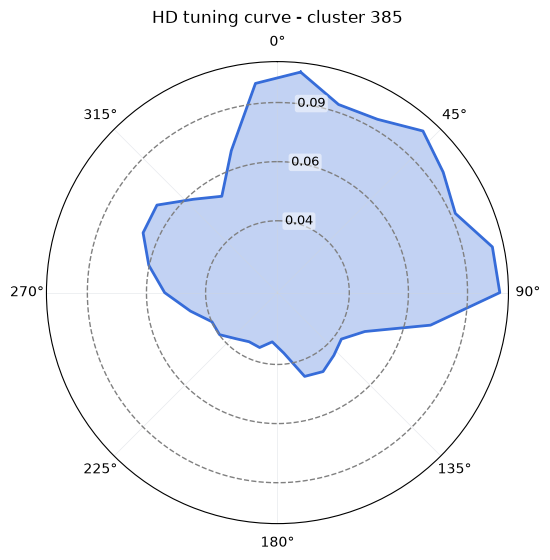

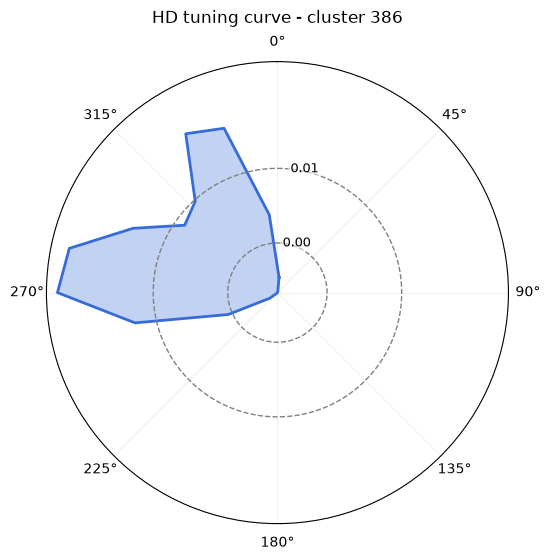

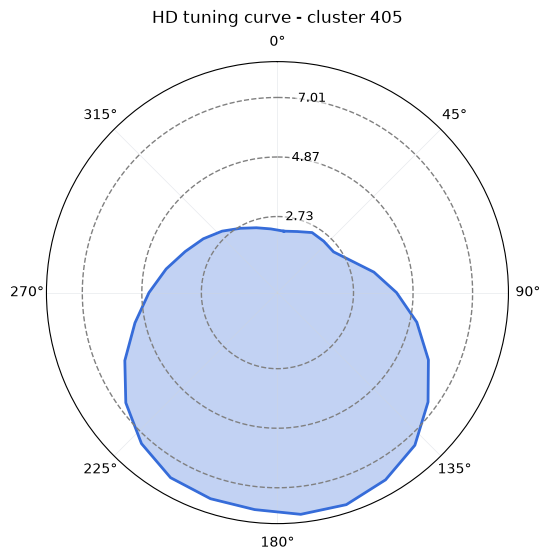

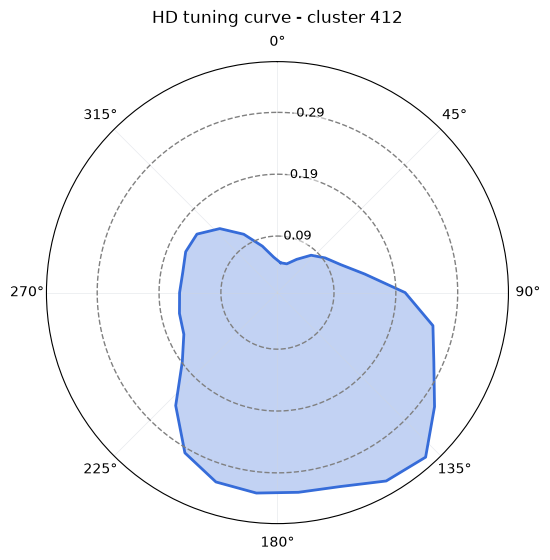

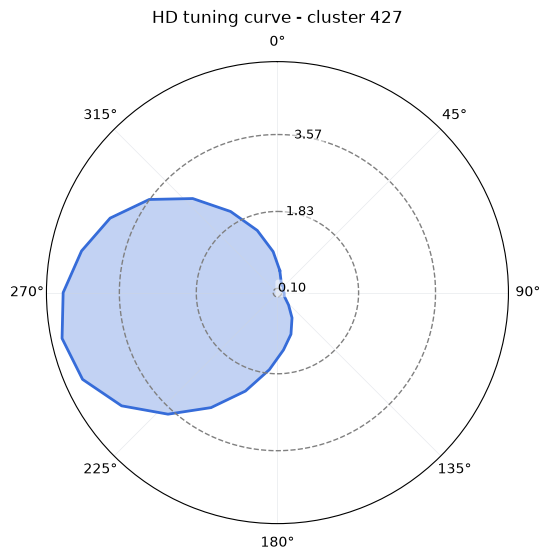

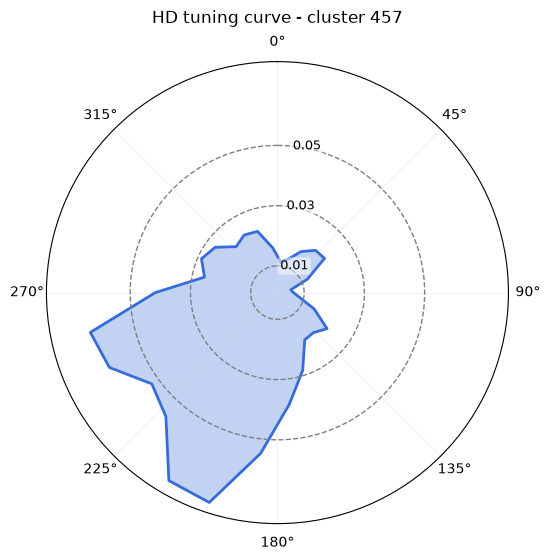

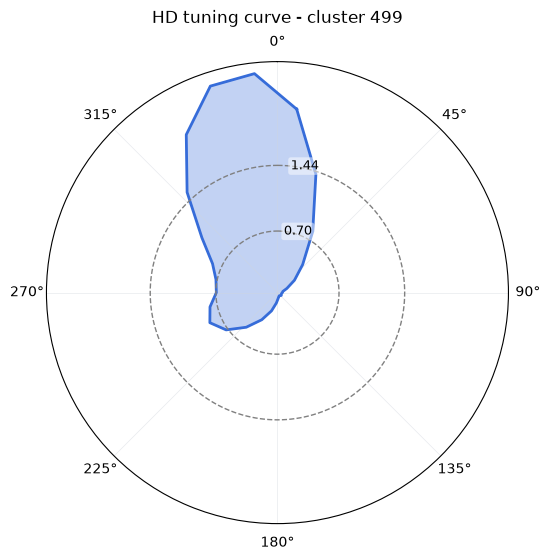

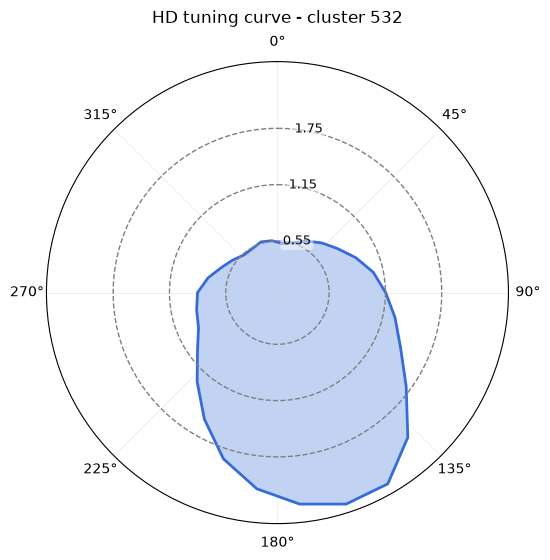

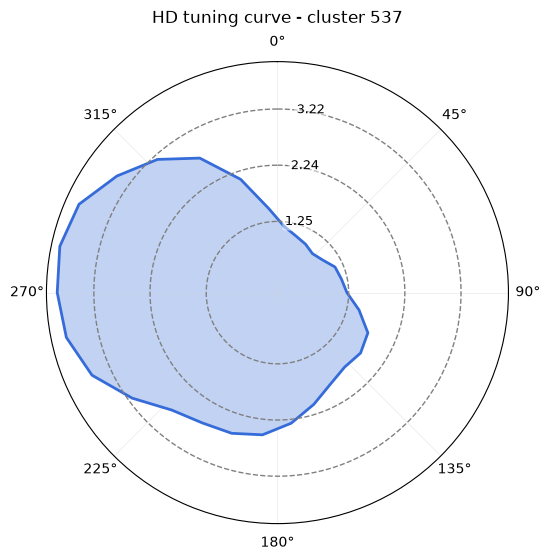

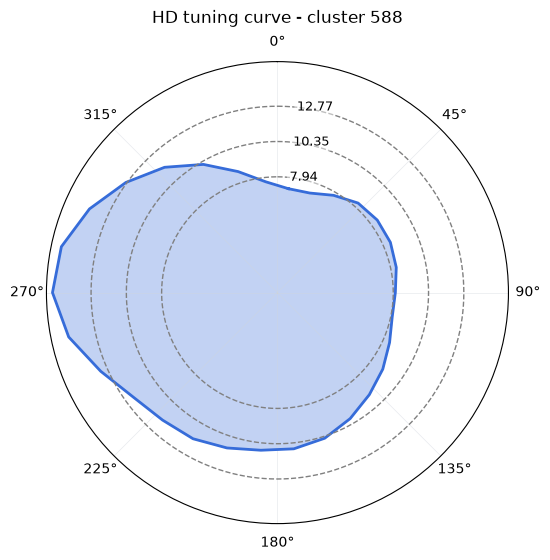

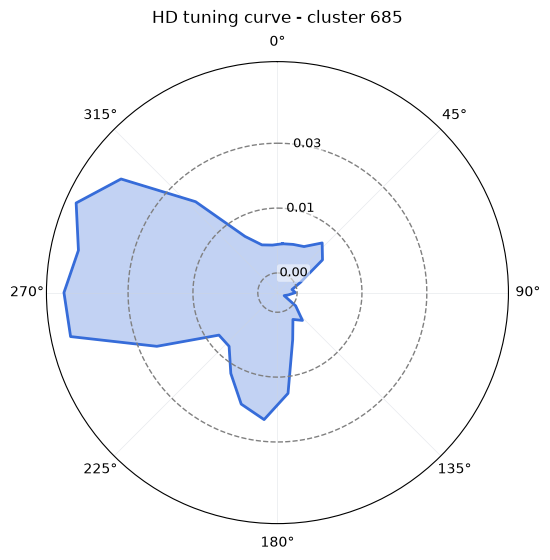

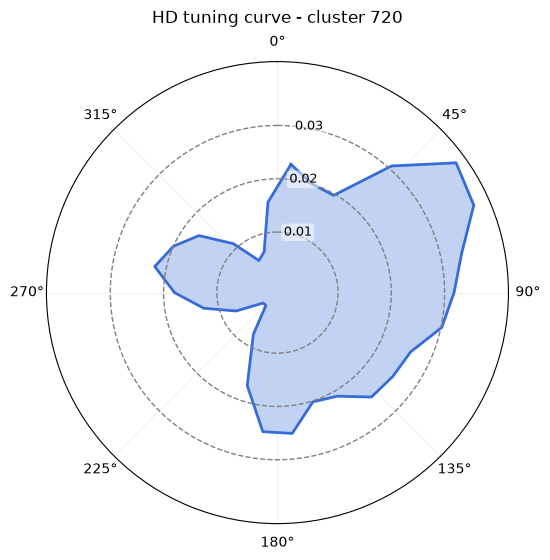

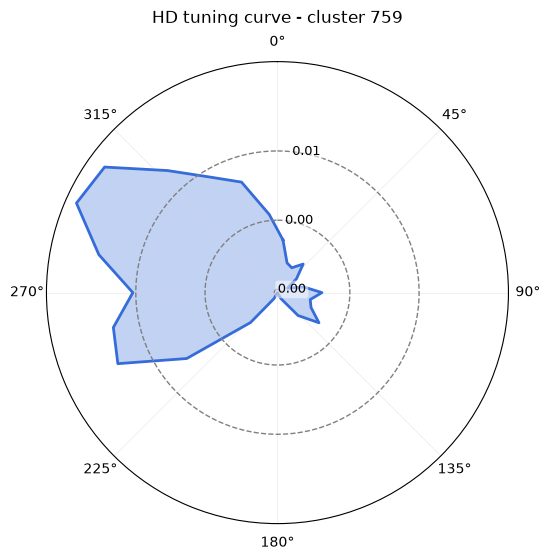

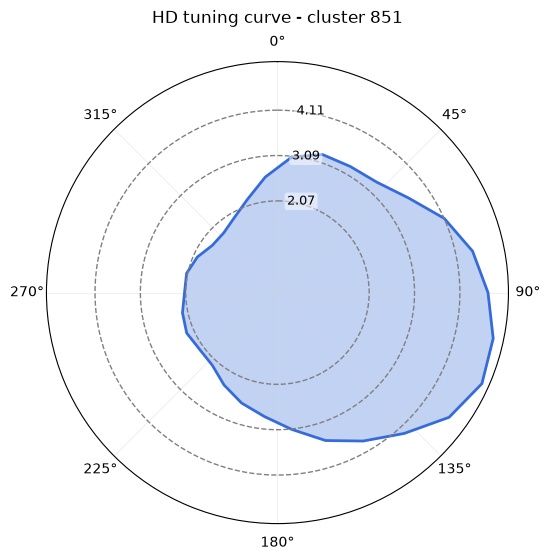

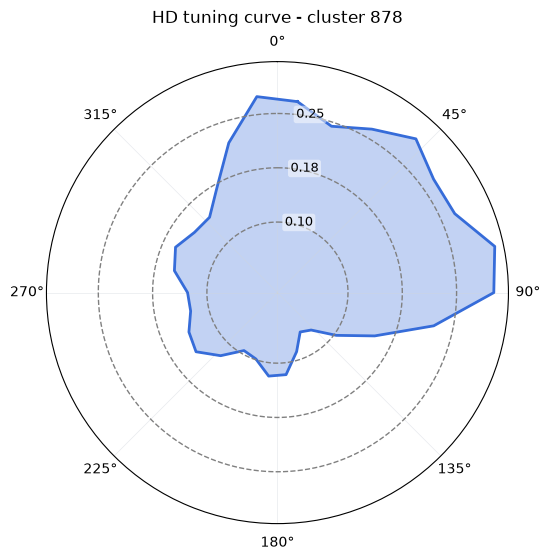

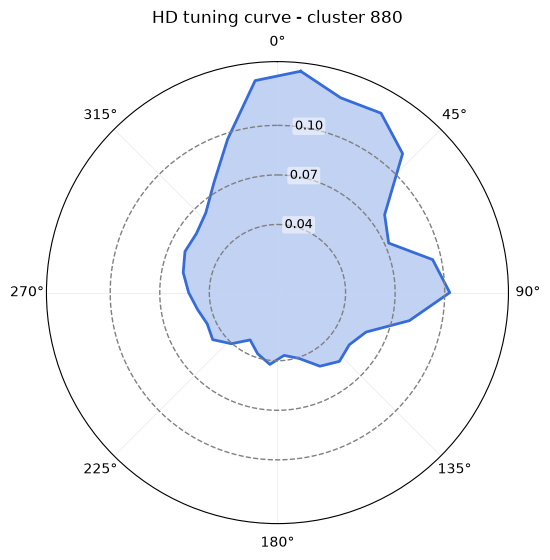

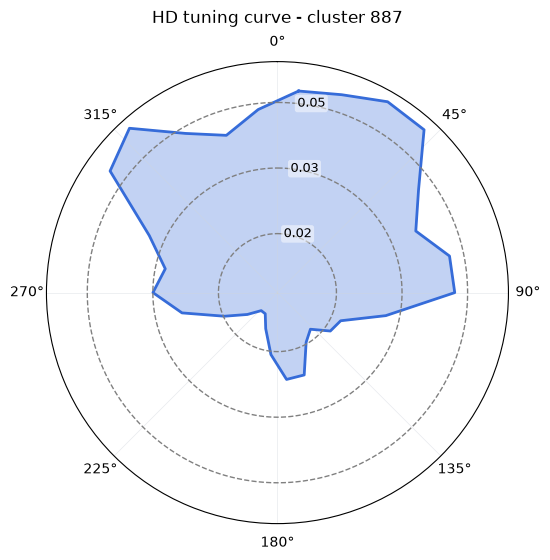

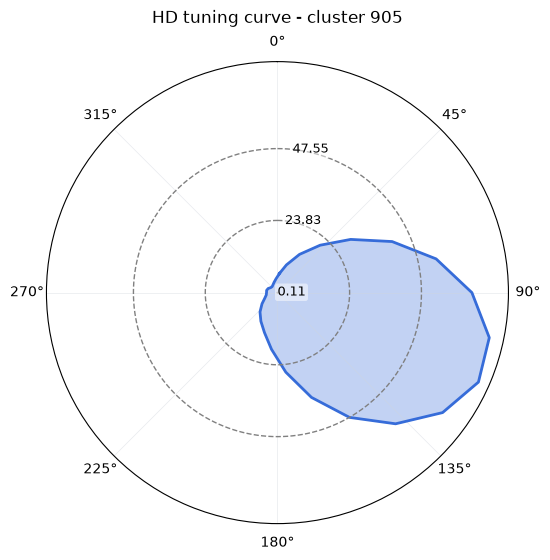

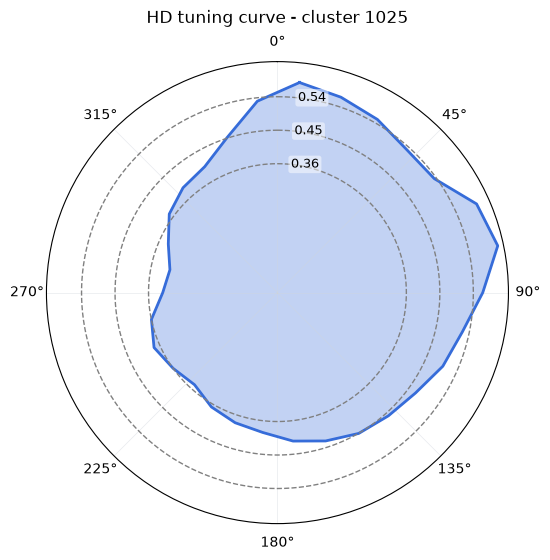

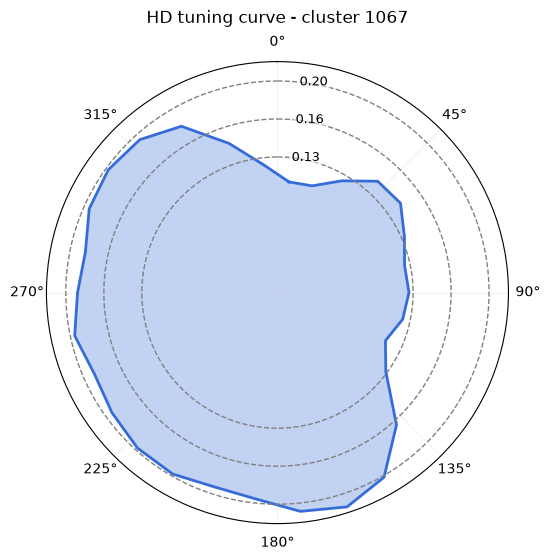

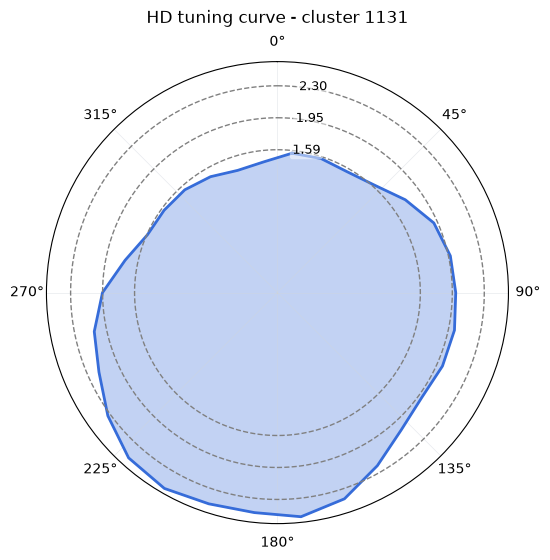

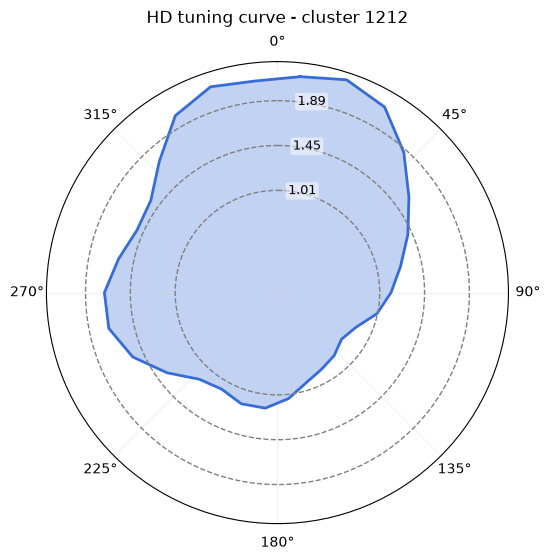

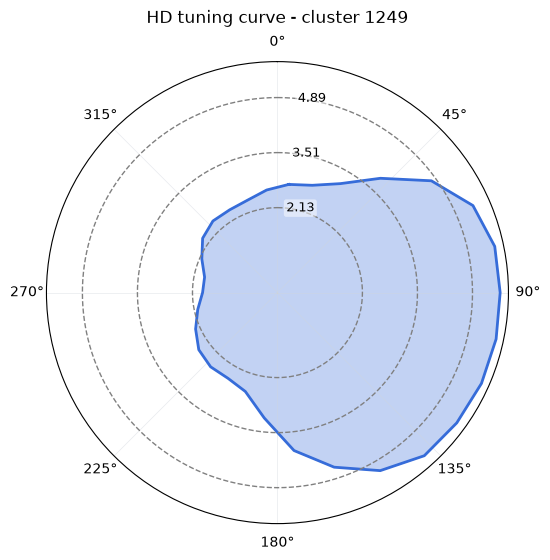

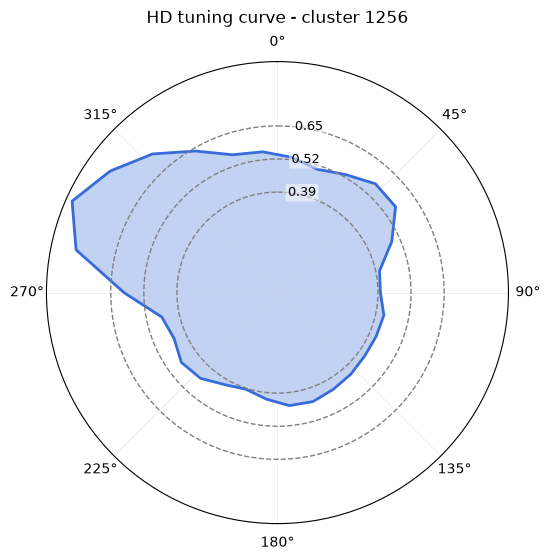

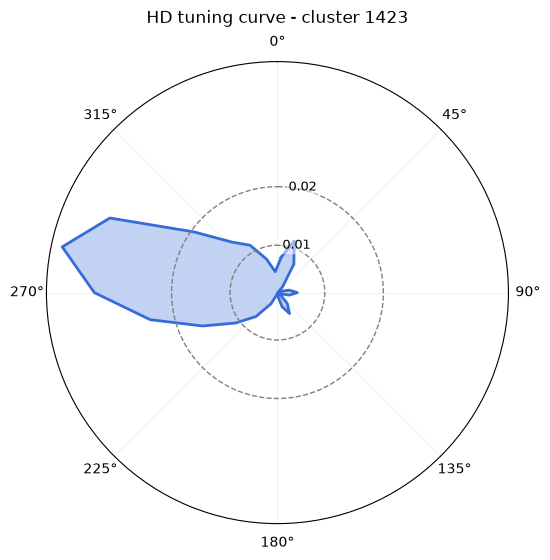

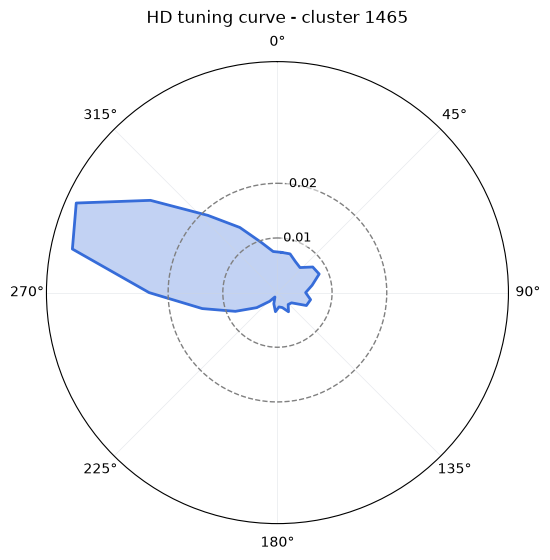

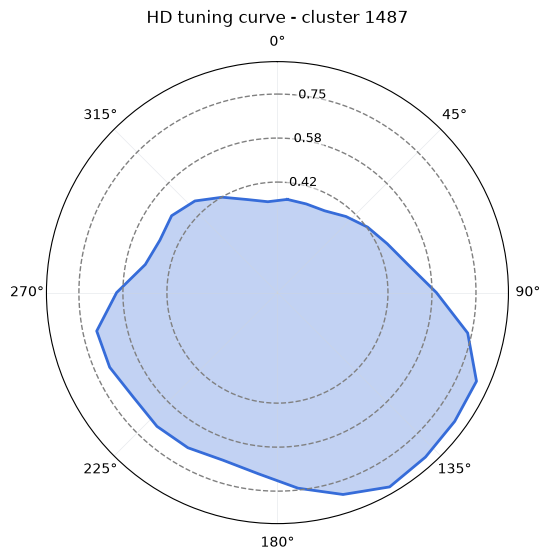

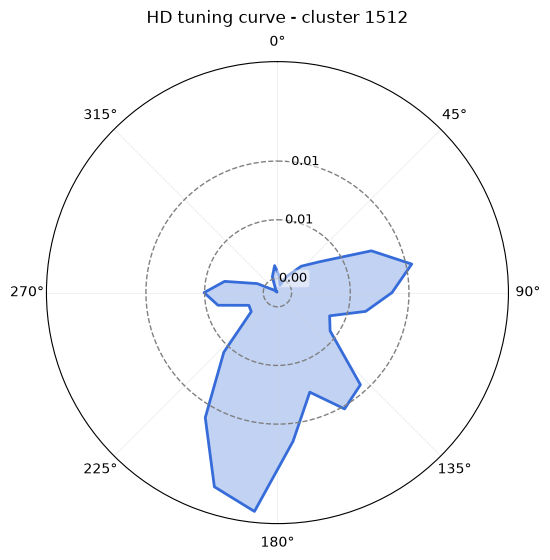

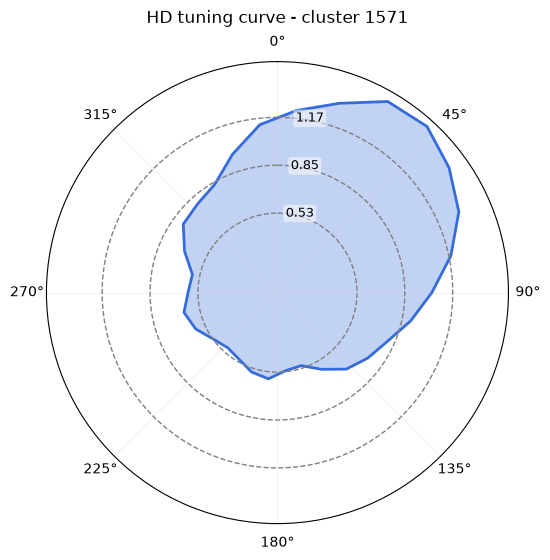

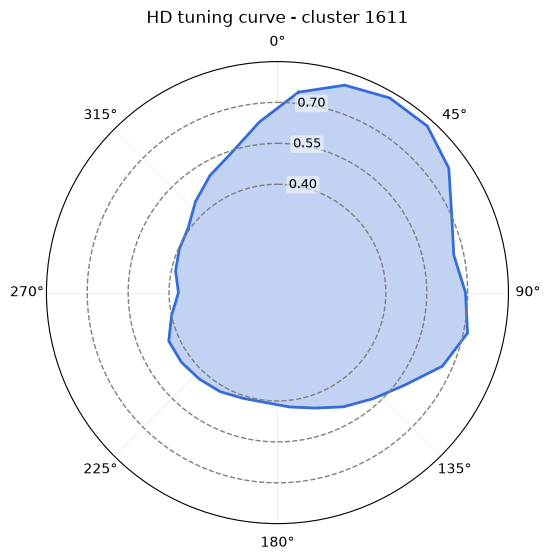

In [7]:
for (_, unit_id), curve in tc.iterrows():
    curve = smooth_tuning_curve(curve, sigma=smooth_sigma)
    result = plot_hd_tuning_curve(
        curve, int(unit_id),
        is_return_line_plot=False,
        is_return_polar_plot=True,
        clockwise=True,
        ring_radii=tuning_curve_reference_radii(curve, levels=(1,)),
    )
    plt.show()
    plt.close(result["polar_fig"])


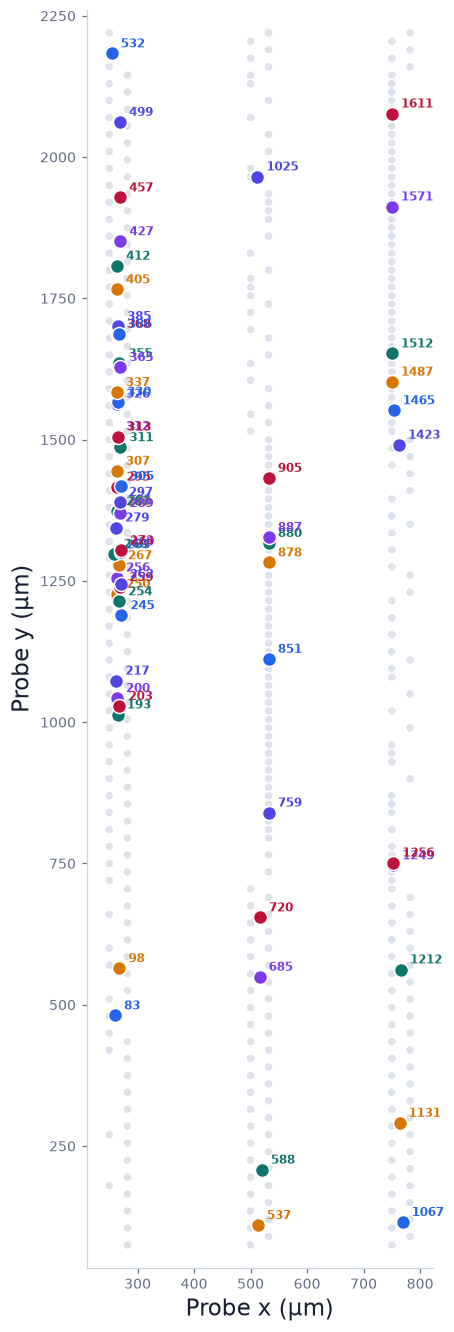

In [8]:
from Utils.probe_plotting import WaveformUnitPlotCollection

plot_unit_ids = tc.index.get_level_values("unit_id").tolist()
unit_plots = WaveformUnitPlotCollection(
    f"{session_dir}/data/waveform/Probe{probe_name}",
    plot_unit_ids,
    save_figures=False,
)
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)
position_plot = unit_plots.plot_unit_locations(show_other_units=False, ax=ax)
ax.get_legend().remove()
plt.show()
plt.close(fig)


In [9]:
rf_session_dir = Path(base_dir) / date / f"{date}_{rf_session_id}"
rf_source = (rf_session_dir / "data/rfmapping/good/-100_400_1ms" / f"Probe{probe_name}"
             / f"regular_unitsSpikeCounts_{date}_{rf_session_id}.rfmap")
rf_maps = load_rfmap(rf_source)
hd_unit_ids = set(tc.index.get_level_values("unit_id"))
rf_maps = RFMapList([item for item in rf_maps if int(item.unit_id) in hd_unit_ids], rf_source)
rf_rate_maps = rf_maps.to_firing_rate(reconstruct_presentations=True).mean_rate(
    *rf_response_window_s, show_progress=False,
)

# Native full 2-D rate maximum, without smoothing or a detection-mask restriction.
# Ties use the first native (y, x) bin; missing/nonpositive maps have no RF arrow.
rf_peaks = pd.DataFrame(np.nan, index=tc.index,
                       columns=["rf_ego_deg", "rf_peak_y_deg", "rf_peak_hz", "rf_peak_ties"])
for rf_map in rf_rate_maps:
    rates = rf_map.to_2d_array()
    if not np.isfinite(rates).any() or np.nanmax(rates) <= 0:
        continue
    y, x = np.unravel_index(np.nanargmax(rates), rates.shape)
    rf_peaks.loc[(probe_name, int(rf_map.unit_id))] = [
        (rf_map.x_positions[x] + 180) % 360 - 180,
        rf_map.y_positions[y], rates[y, x], np.count_nonzero(rates == rates[y, x]),
    ]
print(f"RF peaks: {rf_peaks.rf_ego_deg.notna().sum()} / {len(tc)} HD cells; source: {rf_source}")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/senzailab/Kai/#Recording/m22/261008/261008_3/data/rfmapping/good/-100_400_1ms/ProbeA/regular_unitsSpikeCounts_261008_3.rfmap'

### HD forward and RF ego peak directions
All cells lie on one circle, with same-bin display offsets. Gray arrows run from the center to each cell (HD forward). Red arrows start at each cell and turn clockwise by its RF ego angle: displayed direction = displayed HD + RF ego. Arrow length is fixed and does not encode firing rate.

RF ego is the horizontal coordinate of the native full 2-D firing-rate maximum over the configured response window. HD and RF are paired within the same mouse, date, and probe by unit ID. The original HD preferences and RF angles remain unchanged; display offsets rotate both arrows together. Missing RF peaks retain their HD dots and gray arrows.


In [ ]:
# Use the same smoothed curves as the individual HD panels above.
preferred_direction = tc.apply(
    lambda curve: smooth_tuning_curve(curve, sigma=smooth_sigma).idxmax(), axis=1,
).rename("preferred_direction_deg")

# Display offsets stay strictly inside each peak bin; preferred_direction is unchanged.
peak_groups = preferred_direction.groupby(preferred_direction)
within_bin_index = peak_groups.cumcount()
cells_per_bin = peak_groups.transform("size")
bin_width = 360 / bins
display_direction = preferred_direction + (
    (within_bin_index + 0.5) / cells_per_bin - 0.5
) * bin_width
theta = np.deg2rad(display_direction.to_numpy(dtype=float))
ring_radius = np.ones(len(preferred_direction))

rf_direction = np.deg2rad(display_direction + rf_peaks.rf_ego_deg)
cell_x, cell_y = np.sin(theta), np.cos(theta)
rf_tip_x = cell_x + rf_arrow_length * np.sin(rf_direction)
rf_tip_y = cell_y + rf_arrow_length * np.cos(rf_direction)
rf_tip_theta = np.arctan2(rf_tip_x, rf_tip_y)
rf_tip_radius = np.hypot(rf_tip_x, rf_tip_y)

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"}, facecolor="white")
ax.set_facecolor("white")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
circle_theta = np.linspace(0, 2 * np.pi, 361)
ax.plot(circle_theta, np.ones_like(circle_theta), color="0.75", linewidth=1, zorder=1)
for angle in theta:
    ax.annotate("", xy=(angle, 1), xytext=(angle, 0),
                arrowprops=dict(arrowstyle="->", color="0.65", lw=0.8,
                                shrinkA=0, shrinkB=0, mutation_scale=9), zorder=1)
for angle, tip_angle, tip_radius in zip(theta, rf_tip_theta, rf_tip_radius):
    if np.isfinite(tip_angle):
        ax.annotate("", xy=(tip_angle, tip_radius), xytext=(angle, 1),
                    arrowprops=dict(arrowstyle="->", color="#c43c32", lw=1.4,
                                    shrinkA=0, shrinkB=0, mutation_scale=12), zorder=2)
ax.scatter(theta, ring_radius, s=25, c=np.deg2rad(preferred_direction), cmap="hsv", vmin=0, vmax=2 * np.pi,
           edgecolors="black", linewidths=0.5, zorder=3)
# Alternate labels inside/outside the circle to keep crowded bins readable.
for angle, offset_index, (_, unit_id) in zip(theta, within_bin_index, preferred_direction.index):
    degrees = np.rad2deg(angle) % 360
    outside = offset_index % 2 == 0
    align_left = (degrees < 180) == outside
    ax.text(angle, 1.035 if outside else 0.965, str(unit_id),
            rotation=(180 - degrees) % 180 - 90, rotation_mode="anchor",
            fontsize=7, color="black", ha="left" if align_left else "right", va="center")
ax.set_ylim(0, 1 + rf_arrow_length + 0.12)
ax.set_xticks(np.deg2rad(np.arange(0, 360, 30)))
ax.set_yticks([])
ax.spines["polar"].set_visible(False)
ax.grid(color="0.88", linewidth=0.7)
ax.set_title(f"{Path(base_dir).name} · {date} · HD session {num_of_rec} / RF session {rf_session_id} · Probe {probe_name}\n"
             f"{len(preferred_direction)} HD cells · {rf_peaks.rf_ego_deg.notna().sum()} RF peak arrows · RF {rf_response_window_s[0]:g}–{rf_response_window_s[1]:g} s",
             color="black", pad=22)
fig.text(0.5, 0.035, "Gray: center → cell = HD forward     Red: cell → RF ego peak",
         ha="center", fontsize=10, color="black")
fig.text(0.5, 0.015, "Same-bin offsets are display only; arrow lengths do not encode firing rate.",
         ha="center", fontsize=9, color="0.3")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
plt.close(fig)
